# Frequency Controls and Prospective VUS Application

## Consolidated recomputation — empirical support and threshold stability in a RAS-MAPK panel

## The question

Can panel-specific computational-evidence thresholds (PP3/BP4) be derived for ten RAS-MAPK
genes, and at what evidence strength?

The short answer this notebook reaches: **the limiting factor is not predictor discrimination
but empirical resolution in the benign tail.** AUROC is 0.963 for EVEE and 0.980 for REVEL on
a 331-pathogenic / 104-benign reference set. Discrimination is not the problem. Locating a
threshold precisely in the extreme tail is, because the tail is where benign controls are
scarcest.

## What is measured, in order

**Empirical tail support (step 4).** How many benign reference variants occupy the score
region where published REVEL thresholds sit. This requires no estimator at all, which makes
it immune to objections about ours.

**Resolution bound (steps 4b–4c).** Since `LR+ = TPR/FPR` and `TPR ≤ 1`, the constraint
`FPR ≤ 1/LR_target` binds at any threshold and any sensitivity. Each evidence level therefore
imposes an absolute ceiling on the false-positive rate, and a reference set can only support
that level if it can resolve an FPR below the ceiling. The threshold-dependent version follows,
because the observed sensitivity makes the requirement harsher than the best case.

**Positive control (step 6).** REVEL has published thresholds. This estimator applied to REVEL
should land near them. It does not, and step 13 converts that distance into an operational
reading: what fraction of a real VUS cohort each threshold would qualify.

**Where the controls come from (steps 7–8b).** Frequency-qualified controls under the correct
VCEP criteria, and then a decomposition of where candidate controls are lost. This settles a
question the resolution bound raises immediately — whether a larger population resource would
close the gap.

**Stability (steps 9–12).** How far the threshold moves when the reference tail changes:
composition perturbation, bootstrap of the benign side, removal of k controls,
leave-one-gene-out, and replication of the downstream effect on an unselected VUS cohort.

## What the notebook found, in brief

Working through it, three things came out that were not the original question.

**The two routes to a benign control are not independent.** The frequency criterion recovers
66% of the curated benign set, and none of the common missense variants in these genes carries
a pathogenic classification. A larger population resource would return variants the reference
set already contains, so the shortfall is not in the frequency source.

**The derived thresholds are operationally nonselective.** Applied to 1,146 unselected ClinVar
missense VUS, the supporting threshold derived here qualifies 83% of them for REVEL and 78%
for EVEE, against 24% and 19% for the published values. This is why the absolute numbers are
not candidate cutoffs.

**Between-predictor instability was an artefact of scale.** On the rank-invariant measure EVEE
and REVEL are close (0.087 vs 0.077 at strong); the apparent 2.6× difference exists only in
score units, which are not comparable across predictors.

## What was corrected relative to an earlier version

**Haldane–Anscombe.** The earlier version computed `(TP+0.5)/(Npos+0.5)`, which is not the
standard correction: adding 0.5 to all four cells makes the denominators `Npos+1` and `Nneg+1`.
The error inflated LR+. Applied unconditionally here, with the conditional variant kept as a
sensitivity check — correcting only when a zero cell occurs makes the LR discontinuous exactly
where the scan crosses `fp = 0`, which is the tail region this work is about.

**Rounding.** Scores were rounded to three decimals before the scan. In a study whose argument
rests on three or four benign variants in the tail, that is an avoidable degree of freedom. The
scan now runs on raw values.

**Frequency criteria.** BA1 and BS1 thresholds were wrong, and so was the statistic. The
RASopathy VCEP (PTPN11 v2.3, CSpec GN043) uses filtering allele frequency ≥ 0.05% for BA1 and
≥ 0.025% for BS1 — not joint allele frequency at 0.1% and 0.01%.

**Coupling in the stability measure.** The false-positive rate was measured on the resampled
set that produced the threshold. Each threshold is now mapped back onto the fixed benign
distribution.

Correcting the estimator changed the primary estimates negligibly (EVEE strong 0.660 → 0.662,
REVEL strong unchanged). That is worth reporting alongside the correction: the earlier
conclusions did not depend on the defect.

## Why one notebook rather than five

The threshold estimator sits underneath everything: changing it changes the thresholds, which
change the bootstrap intervals, which change the propagation to VUS. Five notebooks chained
through CSV files, each carrying its own copy of the function, is how inconsistent numbers are
produced without anyone noticing. Here there is one function and one set of outputs.

## Companion analysis

A companion audit examines the upstream problem in the same panel: whether functional-assay
coverage is correctly identified for unresolved variants at all
(`mave_coverage_audit.ipynb`). That work concerns evidence *ascertainment*; this one concerns
*calibration validity*. The two failure modes are independent, and both are silent — the
lookup returns a result, the estimator returns a number, neither raises an error.

They also call for different responses. Ascertainment is a tooling problem, fixable by better
identifier handling. The resolution limit is not: no method produces benign controls that do
not exist.

## Scope

This notebook does not select a clinical threshold. The thresholds derived here are
demonstrably more permissive than published calibrations and must not be presented as
candidate cutoffs. What is measured is support and stability. Nothing here is functional
evidence: PP3/BP4, never PS3/BS3.

## 1. Setup

In [1]:
import json, re, time, glob, warnings, urllib.request
from pathlib import Path
import numpy as np, pandas as pd, requests, matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 240); pd.set_option("display.max_columns", 80)
RNG = np.random.default_rng(20260820)

WORK = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path(".")
OUT = WORK / "recomputation"; OUT.mkdir(parents=True, exist_ok=True)

CACHE = WORK / "evee_cache"
for sub in ("variants", "search"):
    (CACHE / sub).mkdir(parents=True, exist_ok=True)
CACHE_RO = [Path(p) for p in glob.glob("/kaggle/input/**/evee_cache", recursive=True)]
CACHE_RO = [p for p in CACHE_RO if p.is_dir() and p.resolve() != CACHE.resolve()]

GENES_PANEL = ["BRAF", "HRAS", "MAP2K1", "MAP2K2", "PTPN11",
               "RAF1", "RIT1", "SHOC2", "SOS1", "SOS2"]

# RASopathy VCEP, PTPN11 v2.3 (CSpec GN043). Filtering allele frequency, not raw AF.
VCEP_BA1_FAF = 0.0005      # 0.05%
VCEP_BS1_FAF = 0.00025     # 0.025%
EXPLORATORY_AF = 0.0001    # 0.01% joint AF - stress test only, NOT BS1

# Evidence-strength ladders. Tavtigian is what this estimator uses; the ClinGen
# targets are carried for sensitivity analysis only.
LADDERS = {
    "Tavtigian (prior 0.10)":     {"supporting": 2.08,  "moderate": 4.33,  "strong": 18.7,  "very_strong": 350.0},
    "ClinGen PP3 (prior 0.0441)": {"supporting": 2.406, "moderate": 5.790, "strong": 33.53, "very_strong": 1124.0},
}
PRIMARY_LADDER = "Tavtigian (prior 0.10)"

# Published REVEL thresholds from independent sources - the positive control.
REVEL_PUBLISHED = {
    "Pejaver supporting": 0.644, "RASopathy VCEP PP3 (supporting)": 0.70,
    "Pejaver moderate": 0.773, "Pejaver strong": 0.932,
}
EVEE_SITE_CUTOFF = 0.80


def locate(fn):
    paths = []
    for pat in (f"/kaggle/input/**/{fn}", f"/kaggle/working/**/{fn}", f"./**/{fn}"):
        paths += [Path(p) for p in glob.glob(pat, recursive=True)]
    paths = [p for p in paths if p.exists()]
    return max(paths, key=lambda p: p.stat().st_mtime) if paths else None


print("output:", OUT)
print("read caches:", [str(p) for p in CACHE_RO] or "(none)")

output: /kaggle/working/recomputation
read caches: ['/kaggle/input/notebooks/fernandosr85/evee-revel/evee_cache', '/kaggle/input/notebooks/fernandosr85/frequency-controls-and-prospective-vus-application/evee_cache', '/kaggle/input/notebooks/fernandosr85/evee-rasopathy/evee_cache']


## 2. Reference set

Loads the comparable set already collected: ClinVar missense variants, ≥2 review stars,
non-conflicting, scored by both EVEE and REVEL. No new EVEE API calls at this step.

In [2]:
p_calib = locate("1_conjunto_comparavel.csv")
p_tier = locate("tier1_com_evee.csv")
if p_calib is None:
    raise FileNotFoundError("1_conjunto_comparavel.csv not found - mount the Path-A output")

calib = pd.read_csv(p_calib).dropna(subset=["evee", "revel"]).copy()
if "gene" not in calib.columns and "GeneSymbol" in calib.columns:
    calib["gene"] = calib["GeneSymbol"]
calib["y"] = (calib["truth"] == "pathogenic").astype(float)
ID = "VariationID" if "VariationID" in calib.columns else "clinvar_id"
calib["cid"] = calib[ID].astype(str)
REF = calib[["cid", "gene", "evee", "revel", "y"]].copy()
REF["source"] = "clinvar_2star"

N_POS, N_NEG = int(REF["y"].sum()), int((REF["y"] == 0).sum())
print(f"reference set: {len(REF)} variants | pat={N_POS} ben={N_NEG}")
print(pd.crosstab(REF["gene"], REF["y"].map({1.0: "pathogenic", 0.0: "benign"})).to_string())

vus = pd.DataFrame()
if p_tier is not None:
    tier = pd.read_csv(p_tier)
    tier["label_norm"] = tier["clinvar_label"].astype(str).str.lower().str.strip()
    vus = tier[tier["label_norm"].isin(["vus", "uncertain significance"])].copy()
    print(f"\nTier-1 VUS: {len(vus)}")
    if "revel" in vus.columns:
        vus_cmp = vus.dropna(subset=["evee", "revel"])
        print(f"  with both scores (complete cases): {len(vus_cmp)}")
    else:
        vus_cmp = vus.dropna(subset=["evee"])
        print("  revel column absent from the VUS set - paired comparison unavailable")
else:
    vus_cmp = pd.DataFrame()
    print("tier1_com_evee.csv not found - propagation step will be skipped")

reference set: 435 variants | pat=331 ben=104
y       benign  pathogenic
gene                      
BRAF         7          71
HRAS         2          19
MAP2K1       2          20
MAP2K2       8          13
PTPN11       7          98
RAF1        13          36
RIT1         0          29
SHOC2        6           3
SOS1        24          36
SOS2        35           6

Tier-1 VUS: 105
  with both scores (complete cases): 105


## 3. EVEE client

Needed at two points: retrieving the controls selected by the VCEP frequency criteria
(step 8) and the unselected VUS cohort (step 12). Reads from cache first; only what is
missing from disk goes to the network.

In [3]:
EVEE_BASE = "https://xix0d0o8le.execute-api.us-east-1.amazonaws.com"
MAX_UNFILTERED_VUS = 1200      # cap on new EVEE calls; sampling is gene-stratified



class EveeClient:
    # Minimal client: reads the on-disk cache first, writes new responses to
    # the writable cache. Only R4b needs network access in this notebook.
    def __init__(self, cache=CACHE, cache_ro=None, min_interval=0.4,
                 timeout=30.0, retries=4):
        self.cache = Path(cache)
        for sub in ("variants", "search"):
            (self.cache / sub).mkdir(parents=True, exist_ok=True)
        self.cache_ro = list(cache_ro if cache_ro is not None else CACHE_RO)
        self.min_interval, self.timeout, self.retries = min_interval, timeout, retries
        self.session = requests.Session(); self._last = 0.0
        self.stats = {"cache": 0, "api": 0, "write_fail": 0}

    def _get(self, path, params=None):
        last = None
        for a in range(self.retries):
            gap = time.monotonic() - self._last
            if gap < self.min_interval:
                time.sleep(self.min_interval - gap)
            self._last = time.monotonic()
            try:
                r = self.session.get(EVEE_BASE + path, params=params, timeout=self.timeout)
            except requests.RequestException as e:
                last = e; time.sleep(2 ** a); continue
            if r.status_code == 404:
                return r
            if r.status_code in (429, 500, 502, 503, 504):
                last = RuntimeError(f"HTTP {r.status_code}"); time.sleep(2 ** a); continue
            r.raise_for_status(); return r
        raise RuntimeError(f"{path}: {last}")

    @staticmethod
    def _slug(t):
        return re.sub(r"[^A-Za-z0-9._-]", "_", str(t))

    def _cached(self, kind, key, fetch):
        name = f"{self._slug(key)}.json"
        fp = self.cache / kind / name
        if fp.exists():
            self.stats["cache"] += 1; return json.loads(fp.read_text())
        for ro in self.cache_ro:
            alt = ro / kind / name
            if alt.exists():
                self.stats["cache"] += 1; return json.loads(alt.read_text())
        v = fetch(); self.stats["api"] += 1
        try:
            fp.write_text(json.dumps(v))
        except OSError:
            self.stats["write_fail"] += 1
        return v

    def record(self, cid, gene=None):
        q = str(cid).strip()
        def fetch_search():
            r = self._get("/variants/search", params={"q": q})
            return [] if r.status_code == 404 else [
                {"variant_id": x["v"], "gene": x.get("g")} for x in r.json()]
        hits = self._cached("search", q, fetch_search)
        if not hits:
            return None
        vid = hits[0].get("variant_id")
        if gene:
            same = [h for h in hits if (h.get("gene") or "").upper() == str(gene).upper()]
            if same:
                vid = same[0]["variant_id"]
        def fetch_variant():
            r = self._get(f"/variants/{vid}")
            return {"__missing__": True} if r.status_code == 404 else r.json()
        d = self._cached("variants", vid, fetch_variant)
        return None if d.get("__missing__") else d


cli = EveeClient()
print("client ready | read caches:", len(CACHE_RO))

client ready | read caches: 3


## 4. Result 1 — empirical tail support, without an estimator

The question that requires no calibration method at all: how many benign reference variants
occupy the region of the score scale where the **published** REVEL thresholds sit?

A count of zero is not evidence of a zero rate. Each row carries the exact binomial
(Clopper–Pearson) interval; with 0 of 104, the 95% upper bound is on the order of 3/104 by
the rule of three.

In [4]:
def binom_ci(k, n, alpha=0.05):
    # Clopper-Pearson exact interval for a proportion.
    lo = 0.0 if k == 0 else stats.beta.ppf(alpha / 2, k, n - k + 1)
    hi = 1.0 if k == n else stats.beta.ppf(1 - alpha / 2, k + 1, n - k)
    return float(lo), float(hi)


def tail_support(frame, col, thresholds):
    ben = frame.loc[frame["y"] == 0, col].to_numpy(float)
    pat = frame.loc[frame["y"] == 1, col].to_numpy(float)
    rows = []
    for name, t in thresholds.items():
        kb = int((ben >= t).sum()); kp = int((pat >= t).sum())
        lo, hi = binom_ci(kb, len(ben))
        rows.append({"threshold_source": name, "threshold": t,
                     "benign_above": kb, "n_benign": len(ben),
                     "benign_frac": kb / len(ben),
                     "benign_frac_95CI": f"[{lo:.4f}, {hi:.4f}]",
                     "pathogenic_above": kp, "n_pathogenic": len(pat)})
    return pd.DataFrame(rows)


sup_revel = tail_support(REF, "revel", REVEL_PUBLISHED)
sup_evee = tail_support(REF, "evee", {"EVEE published site cutoff": EVEE_SITE_CUTOFF})
tail = pd.concat([sup_revel.assign(predictor="REVEL"),
                  sup_evee.assign(predictor="EVEE")], ignore_index=True)
tail.to_csv(OUT / "R1_tail_support.csv", index=False)
print(tail.to_string(index=False))

zero = tail[tail["benign_above"] == 0]
if len(zero):
    print(f"\n*** {len(zero)} published threshold(s) with NO benign reference variant above. "
          "The set offers little direct empirical support for calibrating in that range - "
          "any estimate there depends on smoothing, assumptions, or external information. ***")

               threshold_source  threshold  benign_above  n_benign  benign_frac benign_frac_95CI  pathogenic_above  n_pathogenic predictor
             Pejaver supporting      0.644             4       104     0.038462 [0.0106, 0.0956]               286           331     REVEL
RASopathy VCEP PP3 (supporting)      0.700             3       104     0.028846 [0.0060, 0.0820]               258           331     REVEL
               Pejaver moderate      0.773             1       104     0.009615 [0.0002, 0.0524]               216           331     REVEL
                 Pejaver strong      0.932             0       104     0.000000 [0.0000, 0.0348]                91           331     REVEL
     EVEE published site cutoff      0.800             2       104     0.019231 [0.0023, 0.0677]               160           331      EVEE

*** 1 published threshold(s) with NO benign reference variant above. The set offers little direct empirical support for calibrating in that range - any estimate ther

### 4b. Result 1b — resolution limit, independent of threshold

The previous step counts observations. This one converts the count into an **empirical
resolution bound**.

Since `LR+ = TPR/FPR` and `TPR ≤ 1`, the constraint `FPR ≤ 1/LR_target` binds **at any
threshold and any sensitivity**. Each evidence level therefore imposes an absolute ceiling on
the false-positive rate, and a reference set can only demonstrate that level if it can
resolve an FPR below the ceiling.

The most favourable possible case is observing **zero** false positives: the Clopper–Pearson
upper bound then depends only on `n`. If that bound still exceeds the ceiling, the level is
not demonstrable at that sample size — regardless of predictor, threshold, or estimator.

In [5]:
def n_needed_zero_events(fpr_max, alpha=0.05, sided="two"):
    # Smallest n whose zero-event Clopper-Pearson upper bound falls below fpr_max.
    # With k = 0 the CP upper bound solves (1 - p)^n = a, so n = ln(a) / ln(1 - p).
    a = alpha / 2 if sided == "two" else alpha
    if not (0 < fpr_max < 1):
        return np.nan
    return int(np.ceil(np.log(a) / np.log(1 - fpr_max)))


ZERO_EVENT_BOUND = binom_ci(0, N_NEG)[1]      # CP upper bound at k = 0, n = N_NEG

rows = []
for ladder, targets in LADDERS.items():
    for level, lr in targets.items():
        fpr_max = 1.0 / lr                    # binding even at perfect sensitivity
        rows.append({
            "ladder": ladder, "level": level, "lr_target": lr,
            "max_admissible_fpr": fpr_max,
            "n_needed_two_sided": n_needed_zero_events(fpr_max, sided="two"),
            "n_needed_one_sided": n_needed_zero_events(fpr_max, sided="one"),
            "n_benign_available": N_NEG,
            "zero_event_upper_bound": ZERO_EVENT_BOUND,
            "resolvable_at_current_n": bool(ZERO_EVENT_BOUND < fpr_max),
        })
res_lim = pd.DataFrame(rows)
res_lim.to_csv(OUT / "R1b_resolution_limit.csv", index=False)
print(f"benign controls available: {N_NEG} | CP upper bound at 0 events: "
      f"{100*ZERO_EVENT_BOUND:.2f}%\n")
print(res_lim.round(5).to_string(index=False))

undem = res_lim[~res_lim["resolvable_at_current_n"]]
if len(undem):
    print("\nLEVELS BEYOND THE EMPIRICAL RESOLUTION BOUND at the current n, "
          "for any predictor or threshold:")
    for _, r in undem.iterrows():
        print(f"  {r['ladder']:28s} {r['level']:12s} requires FPR <= {100*r['max_admissible_fpr']:.2f}% "
              f"| minimum n {r['n_needed_two_sided']} | short by {r['n_needed_two_sided'] - N_NEG}")

benign controls available: 104 | CP upper bound at 0 events: 3.48%

                    ladder       level  lr_target  max_admissible_fpr  n_needed_two_sided  n_needed_one_sided  n_benign_available  zero_event_upper_bound  resolvable_at_current_n
    Tavtigian (prior 0.10)  supporting      2.080             0.48077                   6                   5                 104                 0.03485                     True
    Tavtigian (prior 0.10)    moderate      4.330             0.23095                  15                  12                 104                 0.03485                     True
    Tavtigian (prior 0.10)      strong     18.700             0.05348                  68                  55                 104                 0.03485                     True
    Tavtigian (prior 0.10) very_strong    350.000             0.00286                1290                1048                 104                 0.03485                    False
ClinGen PP3 (prior 0.0441)  supportin

In [6]:
# Threshold-dependent version, for comparison with the threshold-free bound above:
# the FPR each published REVEL threshold would need, given its observed sensitivity.
ben = REF.loc[REF["y"] == 0, "revel"].to_numpy(float)
pat = REF.loc[REF["y"] == 1, "revel"].to_numpy(float)
rows = []
for name, t in REVEL_PUBLISHED.items():
    tpr = float((pat >= t).mean())
    kb = int((ben >= t).sum())
    for ladder, targets in LADDERS.items():
        for level in ("strong",):
            need = tpr / targets[level]
            rows.append({"threshold_source": name, "threshold": t, "observed_tpr": tpr,
                         "ladder": ladder, "lr_target": targets[level],
                         "required_fpr": need,
                         "one_benign_would_give": 1 / N_NEG,
                         "observed_benign_above": kb,
                         "cp_upper_at_observed": binom_ci(kb, N_NEG)[1]})
req = pd.DataFrame(rows)
req.to_csv(OUT / "R1c_required_fpr.csv", index=False)
print(req.round(5).to_string(index=False))
print(f"\nA single benign variant above the threshold already equals 1/{N_NEG} = "
      f"{100/N_NEG:.2f}% - compare with the required_fpr column.")

               threshold_source  threshold  observed_tpr                     ladder  lr_target  required_fpr  one_benign_would_give  observed_benign_above  cp_upper_at_observed
             Pejaver supporting      0.644       0.86405     Tavtigian (prior 0.10)      18.70       0.04621                0.00962                      4               0.09556
             Pejaver supporting      0.644       0.86405 ClinGen PP3 (prior 0.0441)      33.53       0.02577                0.00962                      4               0.09556
RASopathy VCEP PP3 (supporting)      0.700       0.77946     Tavtigian (prior 0.10)      18.70       0.04168                0.00962                      3               0.08199
RASopathy VCEP PP3 (supporting)      0.700       0.77946 ClinGen PP3 (prior 0.0441)      33.53       0.02325                0.00962                      3               0.08199
               Pejaver moderate      0.773       0.65257     Tavtigian (prior 0.10)      18.70       0.03490       

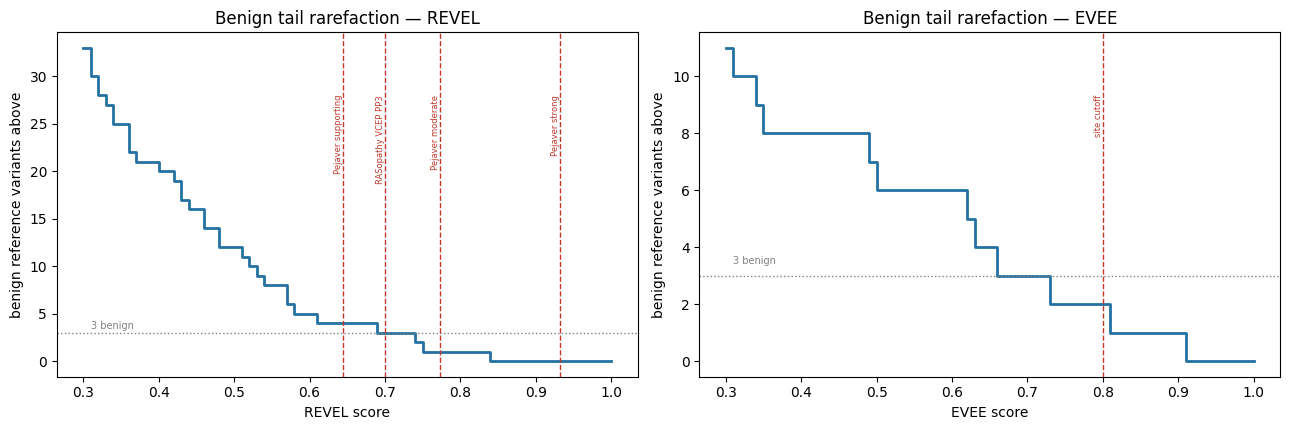

In [7]:
# How the benign tail thins out as the evidence bar rises.
grid = np.linspace(0.3, 1.0, 71)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, col, pub in [(axes[0], "revel", REVEL_PUBLISHED),
                     (axes[1], "evee", {"site cutoff": EVEE_SITE_CUTOFF})]:
    ben = REF.loc[REF["y"] == 0, col].to_numpy(float)
    counts = [(ben >= g).sum() for g in grid]
    ax.step(grid, counts, where="post", lw=2, color="#2471a3")
    ax.axhline(3, ls=":", c="grey", lw=1)
    ax.text(0.31, 3.4, "3 benign", fontsize=7, c="grey")
    for name, t in pub.items():
        ax.axvline(t, ls="--", lw=1, c="#c0392b")
        ax.text(t, max(counts) * 0.85, name[:18], rotation=90, fontsize=6,
                ha="right", va="top", c="#c0392b")
    ax.set_xlabel(f"{col.upper()} score"); ax.set_ylabel("benign reference variants above")
    ax.set_title(f"Benign tail rarefaction — {col.upper()}")
plt.tight_layout(); plt.savefig(OUT / "fig_R1_tail_support.png", dpi=150); plt.show()

## 5. Corrected estimator

Haldane–Anscombe adding 0.5 to all four cells (denominators `Npos+1`, `Nneg+1`), applied
unconditionally by default. The scan runs on raw scores, without rounding.

`ha="conditional"` reproduces the practice of correcting only when a zero cell occurs, and
exists here as a sensitivity analysis — not as the default, because it introduces a
discontinuity in the LR precisely in the tail.

In [8]:
def lr_at(score, y, thr, ha="always"):
    npos, nneg = float((y == 1).sum()), float((y == 0).sum())
    tp = float(((score >= thr) & (y == 1)).sum())
    fp = float(((score >= thr) & (y == 0)).sum())
    fn, tn = npos - tp, nneg - fp
    if ha == "always" or (ha == "conditional" and min(tp, fp, fn, tn) == 0):
        tp, fp, fn, tn = tp + 0.5, fp + 0.5, fn + 0.5, tn + 0.5
    if (fp + tn) == 0 or fp == 0:
        return np.inf
    return (tp / (tp + fn)) / (fp / (fp + tn))


def threshold_for_lr(score, y, lr_target, ha="always"):
    # Lowest raw score whose LR+ reaches the target. No rounding: with three or
    # four benign variants in the tail, rounding is an avoidable degree of freedom.
    score = np.asarray(score, float); y = np.asarray(y, float)
    if (y == 1).sum() == 0 or (y == 0).sum() == 0:
        return np.nan
    for thr in np.unique(score):
        if lr_at(score, y, thr, ha) >= lr_target:
            return float(thr)
    return np.nan


# Sanity: old vs corrected Haldane-Anscombe on the primary set.
def threshold_old(score, y, lr_target):
    score = np.asarray(score, float); y = np.asarray(y, float)
    npos, nneg = (y == 1).sum(), (y == 0).sum()
    for thr in np.unique(np.round(score, 3)):
        tp = float(((score >= thr) & (y == 1)).sum())
        fp = float(((score >= thr) & (y == 0)).sum())
        if ((tp + 0.5) / (npos + 0.5)) / ((fp + 0.5) / (nneg + 0.5)) >= lr_target:
            return float(thr)
    return np.nan


rows = []
for level, lr in LADDERS[PRIMARY_LADDER].items():
    for col in ("evee", "revel"):
        s, y = REF[col].to_numpy(float), REF["y"].to_numpy(float)
        rows.append({"level": level, "lr_target": lr, "predictor": col.upper(),
                     "old_estimator": threshold_old(s, y, lr),
                     "corrected_always": threshold_for_lr(s, y, lr, "always"),
                     "corrected_conditional": threshold_for_lr(s, y, lr, "conditional")})
cmp_est = pd.DataFrame(rows)
cmp_est.to_csv(OUT / "R0_estimator_comparison.csv", index=False)
print("effect of the estimator correction:\n")
print(cmp_est.round(4).to_string(index=False))

effect of the estimator correction:

      level  lr_target predictor  old_estimator  corrected_always  corrected_conditional
 supporting       2.08      EVEE          0.044            0.0442                 0.0442
 supporting       2.08     REVEL          0.213            0.2130                 0.2130
   moderate       4.33      EVEE          0.142            0.1405                 0.1405
   moderate       4.33     REVEL          0.358            0.3580                 0.3580
     strong      18.70      EVEE          0.660            0.6619                 0.6282
     strong      18.70     REVEL          0.601            0.6010                 0.5790
very_strong     350.00      EVEE            NaN               NaN                    NaN
very_strong     350.00     REVEL            NaN               NaN                    NaN


## 6. Result 2 — REVEL positive control

REVEL has published thresholds. This estimator applied to REVEL should land near them. The
difference is reported in absolute units — the REVEL score is not a ratio scale, so "three
times lower" would carry no interpretation.

In [9]:
s, y = REF["revel"].to_numpy(float), REF["y"].to_numpy(float)
rows = []
for ladder, targets in LADDERS.items():
    for level in ("supporting", "moderate", "strong"):
        t = threshold_for_lr(s, y, targets[level])
        pub = {"supporting": 0.644, "moderate": 0.773, "strong": 0.932}[level]
        rows.append({"ladder": ladder, "level": level, "lr_target": targets[level],
                     "our_threshold": t, "pejaver_published": pub,
                     "difference": (t - pub) if np.isfinite(t) else np.nan})
pc = pd.DataFrame(rows)
pc.to_csv(OUT / "R2_revel_positive_control.csv", index=False)
print(pc.round(4).to_string(index=False))
print(f"\nadditional reference: the RASopathy VCEP applies PP3 at Supporting only, "
      f"with REVEL >= 0.70")
print("\nIf our thresholds are substantially lower, the absolute values must NOT "
      "be presented as candidate clinical cutoffs. What holds is the "
      "support-and-stability argument.")

                    ladder      level  lr_target  our_threshold  pejaver_published  difference
    Tavtigian (prior 0.10) supporting      2.080          0.213              0.644      -0.431
    Tavtigian (prior 0.10)   moderate      4.330          0.358              0.773      -0.415
    Tavtigian (prior 0.10)     strong     18.700          0.601              0.932      -0.331
ClinGen PP3 (prior 0.0441) supporting      2.406          0.247              0.644      -0.397
ClinGen PP3 (prior 0.0441)   moderate      5.790          0.432              0.773      -0.341
ClinGen PP3 (prior 0.0441)     strong     33.530          0.745              0.932      -0.187

additional reference: the RASopathy VCEP applies PP3 at Supporting only, with REVEL >= 0.70

If our thresholds are substantially lower, the absolute values must NOT be presented as candidate clinical cutoffs. What holds is the support-and-stability argument.


## 7. Population frequency under the VCEP criteria

The gnomAD API has changed shape more than once and the filtering-allele-frequency field has
no stable name across versions. This cell tries several query shapes against one gene and
prints the server error on failure, so the working shape can be identified without guessing.

In [10]:
GNOMAD_URL = "https://gnomad.broadinstitute.org/api"
GNOMAD_DATASET = "gnomad_r4"

# Candidate shapes for the FAF field, tried in order. The server error is printed
# on failure so the working shape can be identified without guessing.
FAF_SHAPES = [
    ("joint fafmax (gnomAD v4)",
     "variant_id rsids consequence "
     "joint { ac an fafmax { faf95_max faf95_max_gen_anc } } "
     "exome { ac an } genome { ac an }"),
    ("exome fafmax",
     "variant_id rsids consequence "
     "exome { ac an fafmax { faf95_max faf95_max_gen_anc } } "
     "genome { ac an }"),
    ("joint faf95 grpmax",
     "variant_id rsids consequence joint { ac an faf95 { grpmax } } "
     "exome { ac an } genome { ac an }"),
    ("exome faf95 popmax",
     "variant_id rsids consequence exome { ac an faf95 { popmax popmax_population } } "
     "genome { ac an }"),
    ("exome faf95 grpmax",
     "variant_id rsids consequence exome { ac an faf95 { grpmax grpmax_group } } "
     "genome { ac an }"),
    ("no faf (fallback: joint AF only)",
     "variant_id rsids consequence exome { ac an } genome { ac an }"),
]


def gnomad_query(symbol, fields, dataset=GNOMAD_DATASET, timeout=180, retries=4):
    q = ("query V($symbol: String!, $dataset: DatasetId!) {"
         "  gene(gene_symbol: $symbol, reference_genome: GRCh38) {"
         f"    variants(dataset: $dataset) {{ {fields} }}"
         "  } }")
    payload = {"query": q, "variables": {"symbol": symbol, "dataset": dataset}}
    last = None
    for a in range(retries):
        try:
            r = requests.post(GNOMAD_URL, json=payload, timeout=timeout,
                              headers={"Content-Type": "application/json"})
            body = r.json()
        except Exception as exc:
            last = exc; time.sleep(10 * (a + 1)); continue
        if body.get("errors"):
            raise RuntimeError(str(body["errors"])[:400])   # schema error: do not retry
        g = (body.get("data") or {}).get("gene")
        if g is None:
            last = RuntimeError("gene not returned"); time.sleep(10 * (a + 1)); continue
        return g.get("variants") or []
    raise RuntimeError(str(last))


WORKING_FIELDS, WORKING_NAME = None, None
for name, fields in FAF_SHAPES:
    try:
        probe = gnomad_query("HRAS", fields)
        WORKING_FIELDS, WORKING_NAME = fields, name
        print(f"OK: '{name}' | {len(probe)} variants")
        if probe:
            print(json.dumps(probe[0], indent=2)[:600])
        break
    except Exception as exc:
        print(f"FAILED '{name}': {str(exc)[:220]}\n")

if WORKING_FIELDS is None:
    print("*** no query shape worked - check internet access and the current schema ***")

OK: 'joint fafmax (gnomAD v4)' | 1490 variants
{
  "variant_id": "11-532564-G-T",
  "rsids": [],
  "consequence": "3_prime_UTR_variant",
  "joint": {
    "ac": 0,
    "an": 1570946,
    "fafmax": {
      "faf95_max": null,
      "faf95_max_gen_anc": null
    }
  },
  "exome": {
    "ac": 0,
    "an": 1418602
  },
  "genome": null
}


In [11]:
def extract_freq(v):
    # Return (faf, joint_af). faf is the highest filtering allele frequency
    # exposed by whichever schema shape worked: gnomAD v4 exposes
    # fafmax { faf95_max } on the joint/exome types; older shapes expose
    # faf95 { grpmax | popmax }. None when the schema has no FAF field.
    faf = None
    for src in ("joint", "exome", "genome"):
        d = v.get(src) or {}
        fm = d.get("fafmax")
        if isinstance(fm, dict):
            val = fm.get("faf95_max")
            if isinstance(val, (int, float)):
                faf = max(faf or 0.0, float(val))
    for src in ("joint", "exome", "genome"):
        d = v.get(src) or {}
        f = d.get("faf95")
        if isinstance(f, dict):
            val = f.get("grpmax", f.get("popmax"))
            if isinstance(val, (int, float)):
                faf = max(faf or 0.0, float(val))
    ac = an = 0
    for src in ("exome", "genome"):
        d = v.get(src) or {}
        ac += (d.get("ac") or 0); an += (d.get("an") or 0)
    joint = (ac / an) if an else np.nan
    if faf is None:
        j = v.get("joint") or {}
        if j.get("an"):
            joint = (j.get("ac") or 0) / j["an"]
    return faf, joint


gn = pd.DataFrame()
if WORKING_FIELDS:
    rows, failed = [], []
    for g in GENES_PANEL:
        try:
            variants = gnomad_query(g, WORKING_FIELDS)
        except Exception as exc:
            print(f"  {g}: FAILED ({str(exc)[:120]})"); failed.append(g); continue
        for v in variants:
            faf, joint = extract_freq(v)
            if (faf is None or not np.isfinite(faf)) and not np.isfinite(joint):
                continue
            rows.append({"gene": g, "gnomad_id": v.get("variant_id"),
                         "consequence_gnomad": v.get("consequence"),
                         "faf95": faf, "joint_af": joint})
        print(f"  {g}: {len(variants)} variants")
    gn = pd.DataFrame(rows)
    if failed:
        print(f"\n*** failed: {failed} - rerun this cell, gnomAD rate-limits ***")
    if len(gn):
        gn.to_csv(OUT / "R3_gnomad_raw.csv", index=False)
        has_faf = gn["faf95"].notna().sum()
        print(f"\n{len(gn)} variants | with FAF95: {has_faf}")
        if has_faf:
            print(f"  FAF >= {VCEP_BA1_FAF} (BA1 VCEP): {int((gn['faf95'] >= VCEP_BA1_FAF).sum())}")
            print(f"  FAF >= {VCEP_BS1_FAF} (BS1 VCEP): {int((gn['faf95'] >= VCEP_BS1_FAF).sum())}")
        else:
            print("  *** no FAF in the schema - only joint AF available. If proceeding, do NOT "
                  "call these BA1/BS1; label them exploratory frequency controls. ***")
        print(f"  joint AF >= {EXPLORATORY_AF} (exploratory): "
              f"{int((gn['joint_af'] >= EXPLORATORY_AF).sum())}")

  BRAF: 6218 variants
  HRAS: 1490 variants
  MAP2K1: 2857 variants
  MAP2K2: 4100 variants
  PTPN11: 3264 variants
  RAF1: 3791 variants
  RIT1: 1177 variants
  SHOC2: 1812 variants
  SOS1: 7171 variants
  SOS2: 8027 variants

39907 variants | with FAF95: 12444
  FAF >= 0.0005 (BA1 VCEP): 845
  FAF >= 0.00025 (BS1 VCEP): 1155
  joint AF >= 0.0001 (exploratory): 887


## 8. Control sets

Three sets, and the naming matters: only variants meeting FAF ≥ 0.025% may be called BS1. The
joint-AF ≥ 0.01% set is retained as a **stress-test perturbation**, labelled as such — its
value was never a claim about benignity, but a demonstration of what a small change in the
reference tail does to a cutoff.

In [12]:
AA3 = set(("Ala Arg Asn Asp Cys Gln Glu Gly His Ile Leu Lys Met Phe Pro Ser Thr "
           "Trp Tyr Val Sec Pyl").split())
_P = re.compile(r"\(p\.([A-Z][a-z]{2})(\d+)([A-Z][a-z]{2}|=|Ter|del|dup|fs)")


def is_missense(name):
    m = _P.search(str(name))
    if not m:
        return False
    ref, alt = m.group(1), m.group(3)
    tail = str(name)[m.end():m.end() + 6]
    if alt in ("=", "Ter", "fs", "del", "dup") or "fs" in tail:
        return False
    return alt in AA3 and alt != ref


CONTROLS = {}
if len(gn):
    gzp = locate("variant_summary.txt.gz")
    if gzp is None:
        gzp = WORK / "variant_summary.txt.gz"
        print("downloading variant_summary.txt.gz ...")
        urllib.request.urlretrieve(
            "https://ftp.ncbi.nlm.nih.gov/pub/clinvar/tab_delimited/variant_summary.txt.gz", gzp)
    USE = ["Name", "GeneSymbol", "ClinicalSignificance", "ReviewStatus", "VariationID",
           "Assembly", "Chromosome", "PositionVCF", "ReferenceAlleleVCF", "AlternateAlleleVCF"]
    chunks = []
    for ch in pd.read_csv(gzp, sep="\t", low_memory=False, chunksize=400_000, usecols=USE):
        ch = ch[(ch["Assembly"] == "GRCh38") & (ch["GeneSymbol"].isin(GENES_PANEL))]
        if len(ch):
            chunks.append(ch)
    cv = pd.concat(chunks, ignore_index=True).drop_duplicates("VariationID")
    cv = cv[cv["Name"].apply(is_missense)].copy()
    cv["key"] = (cv["Chromosome"].astype(str) + "-"
                 + cv["PositionVCF"].astype("Int64").astype(str) + "-"
                 + cv["ReferenceAlleleVCF"].astype(str) + "-"
                 + cv["AlternateAlleleVCF"].astype(str))
    gn["key"] = gn["gnomad_id"].astype(str)
    merged = cv.merge(gn[["key", "faf95", "joint_af"]], on="key", how="inner")
    sig = merged["ClinicalSignificance"].astype(str).str.lower()
    not_plp = ~(sig.str.contains("pathogenic") & ~sig.str.contains("conflict"))
    already = set(REF["cid"])
    fresh = merged[not_plp & ~merged["VariationID"].astype(str).isin(already)]
    print(f"ClinVar missense matched to gnomAD: {len(merged)} | candidates: {len(fresh)}")

    DEFS = {
        "BS1_VCEP (FAF >= 0.025%)": ("faf95", VCEP_BS1_FAF, "BS1"),
        "BA1_VCEP (FAF >= 0.05%)": ("faf95", VCEP_BA1_FAF, "BA1"),
        "exploratory (joint AF >= 0.01%)": ("joint_af", EXPLORATORY_AF, "exploratory"),
    }
    for label, (colf, cut, tag) in DEFS.items():
        if colf not in fresh or fresh[colf].notna().sum() == 0:
            print(f"  {label}: field {colf} unavailable"); continue
        sel = fresh[fresh[colf] >= cut]
        rows = []
        for _, r in sel.iterrows():
            # Fetch through the client, not a cache-only lookup: these variants
            # were selected by the corrected VCEP criteria and were never queried
            # by any earlier notebook, so they are not in any cache.
            try:
                rec = cli.record(r["VariationID"], r["GeneSymbol"])
            except Exception:
                continue
            if rec is None:
                continue
            cons = str(rec.get("consequence_display") or rec.get("consequence") or "")
            ev, rv = rec.get("pathogenicity"), rec.get("gt_revel_c")
            if "missense" not in cons.lower() or ev is None or rv is None:
                continue
            rows.append({"cid": str(r["VariationID"]), "gene": rec.get("gene_name"),
                         "evee": float(ev), "revel": float(rv), "y": 0.0,
                         "source": tag,
                         "clinvar_sig": str(r["ClinicalSignificance"]),
                         "faf95": r.get("faf95"), "joint_af": r.get("joint_af")})
        CONTROLS[label] = pd.DataFrame(rows)
        n_conf = int(CONTROLS[label]["clinvar_sig"].str.contains("onflict").sum()) \
            if len(rows) else 0
        print(f"  {label}: {len(sel)} candidates -> {len(rows)} with an EVEE score "
              f"({n_conf} conflicting) | api={cli.stats['api']} cache={cli.stats['cache']}")
        if len(rows):
            CONTROLS[label].to_csv(
                OUT / f"R3_controls_{tag}.csv", index=False)
            print(CONTROLS[label]["gene"].value_counts().to_string())

ClinVar missense matched to gnomAD: 3049 | candidates: 2810
  BS1_VCEP (FAF >= 0.025%): 36 candidates -> 35 with an EVEE score (23 conflicting) | api=2 cache=70
gene
SOS1      14
SOS2      12
MAP2K1     2
SHOC2      2
BRAF       2
RAF1       1
RIT1       1
MAP2K2     1
  BA1_VCEP (FAF >= 0.05%): 6 candidates -> 6 with an EVEE score (2 conflicting) | api=2 cache=82
gene
SOS1      3
SHOC2     1
MAP2K2    1
SOS2      1
  exploratory (joint AF >= 0.01%): 17 candidates -> 17 with an EVEE score (12 conflicting) | api=4 cache=114
gene
SOS2      5
SOS1      4
SHOC2     2
RAF1      2
PTPN11    1
MAP2K2    1
MAP2K1    1
RIT1      1


In [13]:
# Reference-set variants under study, in the order results should be reported.
SETS = {"primary (ClinVar >=2*)": REF.copy()}
for label, extra in CONTROLS.items():
    if len(extra):
        cols = ["cid", "gene", "evee", "revel", "y", "source"]
        SETS[f"+ {label}"] = pd.concat([REF, extra[cols]], ignore_index=True)
        clean = extra[~extra["clinvar_sig"].str.contains("onflict", na=False)]
        if len(clean) and len(clean) < len(extra):
            SETS[f"+ {label}, conflicting removed"] = pd.concat(
                [REF, clean[cols]], ignore_index=True)

for k, d in SETS.items():
    print(f"{k:46s} pat={int(d['y'].sum()):4d} ben={int((d['y']==0).sum()):4d}")

primary (ClinVar >=2*)                         pat= 331 ben= 104
+ BS1_VCEP (FAF >= 0.025%)                     pat= 331 ben= 139
+ BS1_VCEP (FAF >= 0.025%), conflicting removed pat= 331 ben= 116
+ BA1_VCEP (FAF >= 0.05%)                      pat= 331 ben= 110
+ BA1_VCEP (FAF >= 0.05%), conflicting removed pat= 331 ben= 108
+ exploratory (joint AF >= 0.01%)              pat= 331 ben= 121
+ exploratory (joint AF >= 0.01%), conflicting removed pat= 331 ben= 109


### 8b. Where the control funnel narrows

The resolution bound in step 4b says this panel is short of the benign controls a
ClinGen-strength strong threshold would require. The immediate follow-up is whether a larger
or more ancestrally diverse population resource would close that gap.

That depends on **where** controls are lost, and there are three distinct losses:

1. **Not missense.** Most variants passing a frequency criterion in a gene region are
   intronic, UTR or synonymous. This says nothing about ClinVar — it is what a gene looks like.
2. **Missense, but absent from ClinVar.** A submission gap. A larger population resource does
   not fix it; more clinical reporting would.
3. **In ClinVar, but excluded** as P/LP or already in the calibration set. This one needs
   splitting further: "already in the calibration set" means the frequency route and the
   curated route returned the *same* variant, which bears directly on whether the two sources
   are independent at all.

Conflating the first two would attribute a biological fact to a database limitation, and
ignoring the third would miss the strongest available answer. The cells below measure the
funnel, decompose it, and test the overlap. The reading is chosen by the numbers, not asserted.
Nothing new is queried: everything comes from the gnomAD pull in step 7 and the control sets
in step 8.

*The argument this settles is general and does not depend on which population database is
proposed. If the frequency criterion and the curated benign set largely return the same
variants, then any larger resource returns predominantly what the reference set already holds —
whatever its name or size.*

In [ ]:
# Where does the funnel narrow? A larger population frequency source only helps
# if controls are lost at the frequency step. If the loss happens downstream --
# at the intersection with ClinVar missense records -- then no frequency resource
# closes the gap, and the resolution limit is a property of the panel rather than
# of the source used to characterise it.

if not len(gn):
    print("gnomAD pull unavailable - funnel analysis skipped")
else:
    funnel = []

    def _step(label, n, note=""):
        funnel.append({"step": label, "n": int(n), "note": note})

    _step("gnomAD variants in the 10 genes", len(gn))
    _step("  with FAF95 reported", gn["faf95"].notna().sum())
    _step("  FAF >= BS1 (0.025%)", (gn["faf95"] >= VCEP_BS1_FAF).sum(),
          "frequency criterion alone, all consequences")
    _step("ClinVar missense matched to gnomAD", len(merged))
    _step("  candidates (not P/LP, not already in REF)", len(fresh))
    _step("  candidates with FAF >= BS1", (fresh["faf95"] >= VCEP_BS1_FAF).sum())

    BS1_KEY = "BS1_VCEP (FAF >= 0.025%)"
    n_scored = len(CONTROLS.get(BS1_KEY, []))
    _step("  of those, with an EVEE score", n_scored, "-> usable as controls")

    fun = pd.DataFrame(funnel)
    # This is not one chain. Two branches converge at the candidate step: the
    # frequency branch (gnomAD -> FAF -> BS1) and the clinical branch (ClinVar
    # missense -> candidates). The ClinVar rows are not a subset of the frequency
    # rows, so a retention ratio computed across the join is meaningless and comes
    # out above 1. Compute retention within each branch and mark which is which.
    fun["branch"] = ["frequency"] * 3 + ["clinvar"] * 2 + ["converged"] * 2
    fun["kept_from_previous"] = np.nan
    for _b in ("frequency", "clinvar", "converged"):
        _m = fun["branch"] == _b
        fun.loc[_m, "kept_from_previous"] = (
            fun.loc[_m, "n"] / fun.loc[_m, "n"].shift()).round(4)
    fun.to_csv(OUT / "R3b_control_funnel.csv", index=False)
    print(fun.to_string(index=False))
    print("\nTwo branches converge at the candidate step, so retention is only "
          "meaningful\nwithin a branch - which is why the column restarts.")

    n_freq_pass = int((gn["faf95"] >= VCEP_BS1_FAF).sum())
    n_clinvar_hit = int((fresh["faf95"] >= VCEP_BS1_FAF).sum())

    _cg = res_lim[(res_lim["ladder"].str.startswith("ClinGen"))
                  & (res_lim["level"] == "strong")]
    need = int(_cg["n_needed_two_sided"].iloc[0]) if len(_cg) else None
    short = (need - N_NEG) if need else None

    print("\n" + "=" * 74)
    print(f"frequency criterion alone yields           : {n_freq_pass:,} variants")
    print(f"of which are ClinVar missense candidates   : {n_clinvar_hit:,}")
    print()
    print(f"benign controls available                  : {N_NEG}")
    if need:
        print(f"benign controls needed (ClinGen strong)    : {need}")
        print(f"gap                                        : {short}")
    print(f"BS1 additions actually obtained             : {n_scored}")
    print("=" * 74)
    print("\nThis table mixes distinct losses. The next two cells separate them;\n"
          "do not interpret it on its own.")

    if n_clinvar_hit and n_scored and short and short > 0:
        yield_rate = n_scored / n_clinvar_hit
        print(f"\nObserved yield, candidate -> usable control : {yield_rate:.2f}")
        print(f"Closing the gap of {short} at that yield would require about "
              f"{int(np.ceil(short / yield_rate))} additional")
        print("ClinVar missense candidates in these ten genes.")

In [ ]:
# The funnel above conflates distinct losses. Separate them: of the variants passing
# the frequency criterion, how many are missense at all, and of those, how many carry
# a ClinVar record? The first is a property of the gene (constrained genes carry few
# common missense variants); the second is submission coverage. Neither is addressed
# by a larger population database.

if not len(gn):
    print("gnomAD pull unavailable - decomposition skipped")
else:
    freq_pass = gn[gn["faf95"] >= VCEP_BS1_FAF].copy()
    print(f"variants passing the BS1 frequency criterion: {len(freq_pass):,}\n")
    print("by gnomAD consequence:")
    print(freq_pass["consequence_gnomad"].value_counts().head(12).to_string())

    MIS = freq_pass["consequence_gnomad"].astype(str).str.contains("missense", case=False,
                                                                  na=False)
    n_mis = int(MIS.sum())

    in_clinvar = set(merged["key"])
    n_mis_cv = int(freq_pass.loc[MIS, "key"].isin(in_clinvar).sum())
    n_mis_cand = int((fresh["faf95"] >= VCEP_BS1_FAF).sum())

    print(f"\nof which missense                          : {n_mis:,}")
    print(f"  present in ClinVar (any classification)  : {n_mis_cv:,}")
    print(f"  candidates after P/LP and REF exclusion  : {n_mis_cand:,}")

    decomp = pd.DataFrame([
        {"loss": "1. not missense", "n": len(freq_pass) - n_mis,
         "of_what": "frequency-passing variants",
         "interpretation": "gene composition; not a database limitation"},
        {"loss": "2. missense, absent from ClinVar", "n": n_mis - n_mis_cv,
         "of_what": "common missense variants",
         "interpretation": "submission coverage gap"},
        {"loss": "3. in ClinVar, excluded as P/LP or already in REF",
         "n": n_mis_cv - n_mis_cand, "of_what": "ClinVar-recorded common missense",
         "interpretation": "by design; split in the next cell"},
    ])
    if n_mis_cv - n_mis_cand < 0:
        print("\n*** WARNING: loss 3 is negative. The candidate set is not contained in "
              "the set counted as present in ClinVar, which means the merge keys or the "
              "consequence filter disagree. Inspect before interpreting. ***")
    decomp.to_csv(OUT / "R3c_funnel_decomposition.csv", index=False)
    print()
    print(decomp.to_string(index=False))

    print("\n" + "=" * 74)
    if len(freq_pass):
        print(f"loss 1 - not missense         : {len(freq_pass)-n_mis:,} "
              f"({100*(1-n_mis/len(freq_pass)):.1f}% of frequency-passing)")
    if n_mis:
        print(f"loss 2 - missense, no ClinVar : {n_mis-n_mis_cv:,} "
              f"({100*(1-n_mis_cv/n_mis):.1f}% of common missense)")
        print(f"loss 3 - ClinVar, excluded    : {n_mis_cv-n_mis_cand:,}")
    print("=" * 74)

    if not n_mis:
        print("""
READING: no common missense variants at all in these genes at the BS1 threshold.

The strongest form of the constraint argument: the shortfall cannot be a database
problem, because the variants do not exist at that frequency.""")
    elif n_mis_cv / n_mis > 0.7:
        print("""
READING: ClinVar already covers most common missense variants in these genes.

The shortfall is therefore a property of how few common missense variants exist here at
all, which is constraint. No population database creates variation that is not in the
population, so a larger or more ancestrally diverse resource does not close the gap.""")
    else:
        print("""
READING: a substantial share of common missense variants is absent from ClinVar.

The shortfall is then partly a submission gap rather than pure constraint. More clinical
reporting in these genes would add benign controls. A larger population database still
does not help directly, since the missing step is the clinical record.""")

    print(f"""
Either way, the population-frequency source is not the binding constraint. Of the
{len(freq_pass):,} variants meeting BS1, only {n_mis:,} are missense, and only those can
enter a missense reference set. Expanding the genome panel raises the first number and
leaves the second governed by how much common missense variation these genes carry.""")

In [ ]:
# Loss 3 is typically the largest of the three, and it hides the question that
# matters most: are the frequency route and the curated route independent? A
# variant excluded because it is "already in the calibration set" was reached by
# both. If most of loss 3 is overlap rather than P/LP exclusion, the two sources
# converge on the same small set of variants, and expanding the population
# resource returns what the reference set already holds.

if not len(gn) or not n_mis:
    print("nothing to decompose")
else:
    freq_mis = freq_pass[MIS].copy()
    cv_rows = merged[merged["key"].isin(set(freq_mis["key"]))].copy()

    sig_l = cv_rows["ClinicalSignificance"].astype(str).str.lower()
    is_plp = sig_l.str.contains("pathogenic") & ~sig_l.str.contains("conflict")
    in_ref = cv_rows["VariationID"].astype(str).isin(set(REF["cid"]))

    n_plp_only = int((is_plp & ~in_ref).sum())
    n_ref_only = int((~is_plp & in_ref).sum())
    n_both = int((is_plp & in_ref).sum())
    n_remain = int((~is_plp & ~in_ref).sum())

    # Zero P/LP among common missense is itself a result in a dominant, rare
    # disease panel: the frequency criterion and the pathogenicity criterion are
    # disjoint here. Report it rather than letting it pass as an empty category.
    print(f"common missense present in ClinVar        : {len(cv_rows):,}")
    print(f"  excluded as P/LP only                   : {n_plp_only:,}")
    print(f"  already in the calibration set only     : {n_ref_only:,}")
    print(f"  both                                    : {n_both:,}")
    print(f"  remaining as candidates                 : {n_remain:,}")

    split = pd.DataFrame([
        {"category": "P/LP only", "n": n_plp_only},
        {"category": "already in REF only", "n": n_ref_only},
        {"category": "both", "n": n_both},
        {"category": "remaining candidates", "n": n_remain},
    ])
    split.to_csv(OUT / "R3d_loss3_split.csv", index=False)

    # --- how much of the curated benign set the frequency route rediscovers ----
    n_ref_ben = int((REF["y"] == 0).sum())
    ref_ben_ids = set(REF.loc[REF["y"] == 0, "cid"])
    overlap = int(cv_rows.loc[~is_plp, "VariationID"].astype(str).isin(ref_ben_ids).sum())

    if n_plp_only + n_both == 0:
        print("\n  note: no common missense variant in these genes carries a pathogenic\n"
              "  classification. The frequency criterion and the pathogenicity criterion\n"
              "  are disjoint in this panel - expected for a dominant, rare mechanism,\n"
              "  and worth stating rather than leaving as an empty category.")

    # The candidate count from `fresh` and the count reached here can differ by a
    # variant or two: gnomAD reports one consequence per variant (the most severe),
    # so something ClinVar names missense may appear as e.g. splice_region here.
    if n_remain != n_mis_cand:
        print(f"\n  note: {abs(n_remain - n_mis_cand)} variant(s) differ between this count "
              f"({n_remain}) and the\n  candidate count from step 8 ({n_mis_cand}). gnomAD "
              "reports a single most-severe\n  consequence per variant, so consequence "
              "annotation can disagree with ClinVar's.\n  This does not affect any "
              "conclusion; state it rather than reconciling silently.")

    print("\n" + "=" * 74)
    print(f"benign controls in the reference set      : {n_ref_ben}")
    print(f"of which the BS1 frequency route recovers : {overlap} "
          f"({100*overlap/n_ref_ben:.1f}%)" if n_ref_ben else "")
    print("=" * 74)

    if n_ref_ben and overlap / n_ref_ben > 0.4:
        print("""
READING: the two routes to a benign control are not independent.

The curated benign set and the frequency-qualifying set are largely the same variants. In
these genes a common missense variant is typically one that ClinVar has already classified
as benign with adequate review status, so the frequency route rediscovers the reference set
rather than extending it.

This is the strongest available answer to the question of whether a larger population
resource would help: it would return variants the reference set already contains. The
shortfall is not in the frequency source, and not only in submission coverage -- it is in
how few distinct common missense variants these genes carry at all.""")
    elif n_ref_ben:
        print("""
READING: the two routes are substantially independent.

The frequency route reaches variants the curated set does not, so the sources are
complementary rather than redundant. A larger population resource could then add controls
the reference set lacks, and quantifying that against a broader dataset becomes a concrete
open item rather than a closed question.""")

## 9. Result 3 — composition perturbation

What happens to an apparently calibrated cutoff when the composition of the tail changes. The
gene distribution of the added controls is reported alongside: if they concentrate in one or
two genes, this is a gene-enriched perturbation and must be described as such.

In [14]:
rows = []
for label, d in SETS.items():
    for col in ("evee", "revel"):
        s, y = d[col].to_numpy(float), d["y"].to_numpy(float)
        r = {"set": label, "n_benign": int((y == 0).sum()), "predictor": col.upper()}
        for level, lr in LADDERS[PRIMARY_LADDER].items():
            r[level] = threshold_for_lr(s, y, lr)
        rows.append(r)
comp = pd.DataFrame(rows)
comp.to_csv(OUT / "R4_composition.csv", index=False)
print(comp.round(4).to_string(index=False))

for label, extra in CONTROLS.items():
    if len(extra):
        vc = extra["gene"].value_counts()
        top = vc.iloc[0] / len(extra)
        print(f"\n{label}: gene distribution")
        print(vc.to_string())
        if top >= 0.5:
            print(f"  *** {vc.index[0]} accounts for {100*top:.0f}% of the {len(extra)} added "
                  "controls. Any threshold shift produced by this\n      set is a "
                  "gene-enriched perturbation, not general tail sensitivity, and must be\n"
                  "      reported as such wherever the shift is cited. ***")

                                                   set  n_benign predictor  supporting  moderate  strong  very_strong
                                primary (ClinVar >=2*)       104      EVEE      0.0442    0.1405  0.6619          NaN
                                primary (ClinVar >=2*)       104     REVEL      0.2130    0.3580  0.6010          NaN
                            + BS1_VCEP (FAF >= 0.025%)       139      EVEE      0.0444    0.1650  0.7662          NaN
                            + BS1_VCEP (FAF >= 0.025%)       139     REVEL      0.2550    0.4230  0.7260          NaN
       + BS1_VCEP (FAF >= 0.025%), conflicting removed       116      EVEE      0.0442    0.1636  0.6282          NaN
       + BS1_VCEP (FAF >= 0.025%), conflicting removed       116     REVEL      0.2470    0.3680  0.7260          NaN
                             + BA1_VCEP (FAF >= 0.05%)       110      EVEE      0.0442    0.1421  0.6619          NaN
                             + BA1_VCEP (FAF >= 0.05%)  

## 10. Result 4 — operating-point stability

Bootstrap of the benign side only. Each sampled threshold is converted into two quantities
invariant under monotone transformation of the score:

- **benign-tail fraction** — the share of the **fixed** benign reference at or above the
  threshold. Not a prospective FPR; it is the threshold's position in the empirical
  distribution.
- **qualifying fraction of VUS** — on an external set, complete cases only.

Score-scale width is retained as within-predictor description only: squaring a predictor
preserves ranking, AUROC and the qualifying set while changing every width.

In [15]:
N_BOOT = 2000


def operating_point_stability(frame, col, lr_target, eval_scores=None,
                              n_boot=N_BOOT, rng=None, ha="always"):
    rng = rng or np.random.default_rng(0)
    pat = frame.loc[frame["y"] == 1, col].to_numpy(float)
    ben = frame.loc[frame["y"] == 0, col].to_numpy(float)
    ben_ref = ben.copy()                       # FIXED reference, never the resample
    ths, fracs_ben, fracs_eval = [], [], []
    for _ in range(n_boot):
        b = rng.choice(ben, len(ben), replace=True)
        s = np.r_[pat, b]; y = np.r_[np.ones(len(pat)), np.zeros(len(b))]
        t = threshold_for_lr(s, y, lr_target, ha)
        if not np.isfinite(t):
            continue
        ths.append(t)
        fracs_ben.append(float((ben_ref >= t).mean()))
        if eval_scores is not None and len(eval_scores):
            fracs_eval.append(float((eval_scores >= t).mean()))
    q = lambda a: (float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5))) if len(a) \
        else (np.nan, np.nan)
    out = {"n_ok": len(ths), "frac_unreachable": 1 - len(ths) / n_boot,
           "thr_median": float(np.median(ths)) if ths else np.nan,
           "thr_95": q(ths), "thr_width": (q(ths)[1] - q(ths)[0]) if ths else np.nan,
           "bentail_median": float(np.median(fracs_ben)) if fracs_ben else np.nan,
           "bentail_95": q(fracs_ben),
           "bentail_width": (q(fracs_ben)[1] - q(fracs_ben)[0]) if fracs_ben else np.nan}
    if fracs_eval:
        out.update({"vus_frac_median": float(np.median(fracs_eval)),
                    "vus_frac_95": q(fracs_eval),
                    "vus_frac_width": q(fracs_eval)[1] - q(fracs_eval)[0],
                    "vus_frac_at_ceiling": float(np.mean(np.array(fracs_eval) >= 1.0))})
    out["_thresholds"] = np.asarray(ths, dtype=float)
    return out


BOOT_THRESHOLDS = {}
ev_eval = (vus_cmp["evee"].to_numpy(float) if len(vus_cmp) else None)
rv_eval = (vus_cmp["revel"].to_numpy(float)
           if len(vus_cmp) and "revel" in vus_cmp.columns else None)

rows = []
for ladder, targets in LADDERS.items():
    for level in ("moderate", "strong"):
        for col, ev in [("evee", ev_eval), ("revel", rv_eval)]:
            r = operating_point_stability(REF, col, targets[level], ev,
                                          rng=np.random.default_rng(7))
            # Keep the threshold draws: R4b replays these exact operating points
            # on an independent, unselected VUS set.
            BOOT_THRESHOLDS[(ladder, level, col)] = r.pop("_thresholds")
            rows.append({"ladder": ladder, "level": level, "predictor": col.upper(), **r})
stab = pd.DataFrame(rows)
stab.to_csv(OUT / "R5_operating_point_stability.csv", index=False)
print(stab.round(4).to_string(index=False))
print("\ncompare 'bentail_width' between predictors (invariant); "
      "'thr_width' within a predictor only.")

# A vus_frac_width of 0 on the selected cohort is saturation, not precision: the
# Tier-1 series was filtered to contain high scores, so every bootstrap threshold
# qualifies all of it. Say so, or a reader takes zero width for a tight estimate.
_sat = stab[(stab.get("vus_frac_at_ceiling", pd.Series(dtype=float)) >= 0.5)]
if len(_sat):
    print(f"\n*** {len(_sat)} row(s) have the qualifying fraction at its ceiling in "
          "most bootstrap replicates.\n    A width of zero there is saturation of a "
          "score-selected cohort, NOT a precise\n    estimate. Do not read those "
          "intervals as tight: ***")
    print(_sat[["ladder", "level", "predictor", "vus_frac_median",
                "vus_frac_width", "vus_frac_at_ceiling"]].round(4).to_string(index=False))

                    ladder    level predictor  n_ok  frac_unreachable  thr_median                        thr_95  thr_width  bentail_median                                  bentail_95  bentail_width  vus_frac_median                              vus_frac_95  vus_frac_width  vus_frac_at_ceiling
    Tavtigian (prior 0.10) moderate      EVEE  2000               0.0      0.1405               (0.112, 0.2169)     0.1049          0.2212    (0.1346153846153846, 0.2980769230769231)         0.1635           1.0000                               (1.0, 1.0)          0.0000               1.0000
    Tavtigian (prior 0.10) moderate     REVEL  2000               0.0      0.3670                (0.306, 0.456)     0.1500          0.2115   (0.14423076923076922, 0.2980769230769231)         0.1538           1.0000                (0.9904761904761905, 1.0)          0.0095               0.9480
    Tavtigian (prior 0.10)   strong      EVEE  2000               0.0      0.6619              (0.3388, 0.9068)     0.568

## 11. Result 5 — removal of k controls, and leave-one-gene-out

Bootstrap resamples with replacement and can duplicate observations. Removing controls
measures sensitivity to actual data loss, which is the concrete scenario: if one control is
reclassified, how far does the threshold move?

In [16]:
KS, N_REP = [1, 3, 5, 10], 500
LR_STRONG = LADDERS[PRIMARY_LADDER]["strong"]

rows = []
ben_idx = REF.index[REF["y"] == 0].to_numpy()
for col in ("evee", "revel"):
    base_t = threshold_for_lr(REF[col].to_numpy(float), REF["y"].to_numpy(float), LR_STRONG)
    ben_ref = REF.loc[REF["y"] == 0, col].to_numpy(float)
    base_bt = float((ben_ref >= base_t).mean()) if np.isfinite(base_t) else np.nan
    for k in KS:
        d_thr, d_bt = [], []
        for _ in range(N_REP):
            sub = REF.drop(index=RNG.choice(ben_idx, k, replace=False))
            t = threshold_for_lr(sub[col].to_numpy(float), sub["y"].to_numpy(float), LR_STRONG)
            if np.isfinite(t) and np.isfinite(base_t):
                d_thr.append(t - base_t)
                d_bt.append(float((ben_ref >= t).mean()) - base_bt)
        rows.append({"predictor": col.upper(), "k": k, "base_threshold": base_t,
                     "thr_max_abs_shift": float(np.max(np.abs(d_thr))) if d_thr else np.nan,
                     "bentail_max_abs_shift": float(np.max(np.abs(d_bt))) if d_bt else np.nan})
rem = pd.DataFrame(rows)
rem.to_csv(OUT / "R6_removal_k.csv", index=False)
print(rem.round(4).to_string(index=False))

predictor  k  base_threshold  thr_max_abs_shift  bentail_max_abs_shift
     EVEE  1          0.6619             0.0337                 0.0096
     EVEE  3          0.6619             0.1561                 0.0288
     EVEE  5          0.6619             0.1561                 0.0288
     EVEE 10          0.6619             0.3113                 0.0481
    REVEL  1          0.6010             0.0220                 0.0096
    REVEL  3          0.6010             0.0300                 0.0192
    REVEL  5          0.6010             0.0300                 0.0192
    REVEL 10          0.6010             0.0900                 0.0288


In [17]:
rows = []
for gene in sorted(REF["gene"].dropna().unique()):
    sub = REF[REF["gene"] != gene]
    if (sub["y"] == 0).sum() < 10:
        continue
    r = {"gene_removed": gene,
         "benign_removed": int((REF[REF["gene"] == gene]["y"] == 0).sum())}
    for col, ev in [("evee", ev_eval), ("revel", rv_eval)]:
        b = operating_point_stability(sub, col, LR_STRONG, ev, n_boot=800,
                                      rng=np.random.default_rng(11))
        b.pop("_thresholds", None)
        r[f"{col}_bentail_width"] = b["bentail_width"]
        r[f"{col}_thr_median"] = b["thr_median"]
        r[f"{col}_unreachable"] = b["frac_unreachable"]
    rows.append(r)
logo = pd.DataFrame(rows)
logo.to_csv(OUT / "R7_logo_operating_point.csv", index=False)
print(logo.round(4).to_string(index=False))
print("\nIf the EVEE width stays wider than REVEL across every removal, "
      "the objection 'is this just SOS1/SOS2?' is answered.")

gene_removed  benign_removed  evee_bentail_width  evee_thr_median  evee_unreachable  revel_bentail_width  revel_thr_median  revel_unreachable
        BRAF               7              0.0928           0.6619               0.0               0.0825             0.601                0.0
        HRAS               2              0.0980           0.6165               0.0               0.0784             0.601                0.0
      MAP2K1               2              0.0882           0.6619               0.0               0.0784             0.601                0.0
      MAP2K2               8              0.0938           0.6190               0.0               0.0938             0.601                0.0
      PTPN11               7              0.0928           0.6619               0.0               0.0825             0.579                0.0
        RAF1              13              0.0989           0.6643               0.0               0.0879             0.691                0.0
      

## 12. Result 4b — replicating the propagation on an unselected VUS cohort

The Tier-1 series was assembled by filtering on AlphaMissense ≥ 0.90 and CADD ≥ 30. If REVEL
correlates more strongly with AlphaMissense than EVEE does — plausible, both being
metapredictors trained on similar sets — the selection compresses the REVEL distribution of
those VUS toward high values, and REVEL's smaller propagation would be a consequence of the
filter rather than of the predictor.

A correlation diagnostic computed inside Tier-1 does not settle this: the selection variable
is already truncated, so the correlation suffers range restriction. The valid test is
replication on an **independent, unselected** evaluation set.

Design: the **same bootstrap thresholds** derived from the reference set (retained at step 10)
are re-applied to all ClinVar missense VUS in the ten genes, complete cases only. Only the
evaluation set changes; the calibration uncertainty is held fixed.

In [18]:
unfiltered = pd.DataFrame()
gzp = locate("variant_summary.txt.gz")
if gzp is None:
    print("variant_summary.txt.gz missing - R4b skipped")
else:
    USE = ["Name", "GeneSymbol", "ClinicalSignificance", "ReviewStatus",
           "VariationID", "Assembly"]
    chunks = []
    for ch in pd.read_csv(gzp, sep="\t", low_memory=False, chunksize=400_000, usecols=USE):
        ch = ch[(ch["Assembly"] == "GRCh38") & (ch["GeneSymbol"].isin(GENES_PANEL))]
        if len(ch):
            chunks.append(ch)
    allcv = pd.concat(chunks, ignore_index=True).drop_duplicates("VariationID")
    sig = allcv["ClinicalSignificance"].astype(str).str.lower()
    pool = allcv[sig.str.contains("uncertain significance")
                 & allcv["Name"].apply(is_missense)].copy()
    # Exclude anything already in the calibration set: the evaluation set must be
    # independent of the variants that produced the thresholds.
    pool = pool[~pool["VariationID"].astype(str).isin(set(REF["cid"]))]
    print(f"unfiltered missense VUS across the 10 genes: {len(pool)}")
    print(pool["GeneSymbol"].value_counts().to_string())

    if len(pool) > MAX_UNFILTERED_VUS:
        frac = MAX_UNFILTERED_VUS / len(pool)
        pool = pool.groupby("GeneSymbol", group_keys=False).apply(
            lambda g: g.sample(max(1, int(round(len(g) * frac))), random_state=0))
        print(f"sampled (gene-stratified): {len(pool)}")

unfiltered missense VUS across the 10 genes: 4431
GeneSymbol
SOS1      896
SOS2      825
RAF1      513
BRAF      455
PTPN11    446
MAP2K2    365
SHOC2     310
HRAS      227
MAP2K1    221
RIT1      173
sampled (gene-stratified): 1200


In [19]:
if len(pool):
    cli = EveeClient()
    rows = []
    for n, (_, r) in enumerate(pool.iterrows(), 1):
        try:
            rec = cli.record(r["VariationID"], r["GeneSymbol"])
        except Exception:
            continue
        if rec is None:
            continue
        cons = str(rec.get("consequence_display") or rec.get("consequence") or "")
        ev, rv = rec.get("pathogenicity"), rec.get("gt_revel_c")
        if "missense" not in cons.lower() or ev is None or rv is None:
            continue
        rows.append({"cid": str(r["VariationID"]), "gene": rec.get("gene_name"),
                     "evee": float(ev), "revel": float(rv)})
        if n % 200 == 0:
            print(f"  {n}/{len(pool)} (api={cli.stats['api']}, cache={cli.stats['cache']})",
                  flush=True)
    unfiltered = pd.DataFrame(rows)
    print(f"\nwith both scores: {len(unfiltered)} | source: {cli.stats}")
    if len(unfiltered):
        unfiltered.to_csv(OUT / "R4b_unfiltered_vus.csv", index=False)
        print("\nscore distribution - selected (Tier-1) vs unselected:")
        for col in ("evee", "revel"):
            a = vus_cmp[col].dropna(); b = unfiltered[col].dropna()
            print(f"  {col.upper():6s} Tier-1: median={a.median():.3f} "
                  f"IQR={a.quantile(.75)-a.quantile(.25):.3f} frac>=0.9={float((a>=.9).mean()):.3f}"
                  f"  |  unselected: median={b.median():.3f} "
                  f"IQR={b.quantile(.75)-b.quantile(.25):.3f} frac>=0.9={float((b>=.9).mean()):.3f}")
        print("\n(a much smaller Tier-1 IQR for one predictor indicates compression by selection)")

  200/1200 (api=377, cache=20)
  400/1200 (api=758, cache=34)
  600/1200 (api=1148, cache=36)
  800/1200 (api=1537, cache=46)
  1000/1200 (api=1927, cache=50)
  1200/1200 (api=2312, cache=56)

with both scores: 1146 | source: {'cache': 56, 'api': 2312, 'write_fail': 0}

score distribution - selected (Tier-1) vs unselected:
  EVEE   Tier-1: median=0.910 IQR=0.165 frac>=0.9=0.543  |  unselected: median=0.203 IQR=0.495 frac>=0.9=0.069
  REVEL  Tier-1: median=0.908 IQR=0.140 frac>=0.9=0.514  |  unselected: median=0.409 IQR=0.366 frac>=0.9=0.051

(a much smaller Tier-1 IQR for one predictor indicates compression by selection)


In [20]:
if len(unfiltered):
    rows = []
    for (ladder, level, col), ths in BOOT_THRESHOLDS.items():
        if not len(ths):
            continue
        for eval_name, frame in [("Tier-1 (selected)", vus_cmp),
                                 ("ClinVar VUS (unselected)", unfiltered)]:
            v = frame[col].dropna().to_numpy(float)
            if not len(v):
                continue
            fr = np.array([(v >= t).mean() for t in ths])
            lo, hi = np.percentile(fr, 2.5), np.percentile(fr, 97.5)
            rows.append({"ladder": ladder, "level": level, "predictor": col.upper(),
                         "eval_set": eval_name, "n_eval": len(v),
                         "frac_median": float(np.median(fr)),
                         "frac_2.5": float(lo), "frac_97.5": float(hi),
                         "frac_width": float(hi - lo),
                         "frac_at_ceiling": float((fr >= 1.0).mean())})
    rep = pd.DataFrame(rows)
    rep.to_csv(OUT / "R4b_propagation_replication.csv", index=False)
    print(rep.round(4).to_string(index=False))

    strong = rep[(rep["level"] == "strong") & (rep["ladder"] == PRIMARY_LADDER)]
    print("\nEVEE/REVEL width ratio at the strong level, by evaluation set:")
    for ev_set, g in strong.groupby("eval_set"):
        e = g.loc[g["predictor"] == "EVEE", "frac_width"]
        r_ = g.loc[g["predictor"] == "REVEL", "frac_width"]
        if len(e) and len(r_) and r_.iloc[0] > 0:
            print(f"  {ev_set:28s} {e.iloc[0]/r_.iloc[0]:.2f}")
    print("\nIf the ratio falls near 1 on the unselected set, Result 4 "
          "was a selection effect and leaves the main text.")

                    ladder    level predictor                 eval_set  n_eval  frac_median  frac_2.5  frac_97.5  frac_width  frac_at_ceiling
    Tavtigian (prior 0.10) moderate      EVEE        Tier-1 (selected)     105       1.0000    1.0000     1.0000      0.0000           1.0000
    Tavtigian (prior 0.10) moderate      EVEE ClinVar VUS (unselected)    1146       0.5733    0.4869     0.6309      0.1440           0.0000
    Tavtigian (prior 0.10) moderate     REVEL        Tier-1 (selected)     105       1.0000    0.9905     1.0000      0.0095           0.9480
    Tavtigian (prior 0.10) moderate     REVEL ClinVar VUS (unselected)    1146       0.5777    0.4494     0.6920      0.2426           0.0000
    Tavtigian (prior 0.10)   strong      EVEE        Tier-1 (selected)     105       0.8857    0.5238     1.0000      0.4762           0.0975
    Tavtigian (prior 0.10)   strong      EVEE ClinVar VUS (unselected)    1146       0.1850    0.0602     0.3988      0.3386           0.0000
    Ta

## 13. Result 2b — what each threshold would qualify in a real VUS population

The positive control at step 6 compares thresholds against thresholds. This cell converts the
difference into consequence: **what fraction of unselected missense VUS in the ten genes each
threshold would qualify** at the corresponding level.

It is the most direct argument against reading the thresholds derived here as clinical
cutoffs — more informative than the numerical distance from Pejaver, because it has an
operational reading. A threshold that qualifies the majority of an unselected VUS cohort is
operationally nonselective at that level, whatever its calibration target.

*The study defines no normative target for what fraction of a cohort should qualify, so no
claim is made about which fraction would be appropriate. The statement is comparative:
published thresholds are substantially more selective than the derived ones.*

Runs after step 12 because it depends on the unselected cohort.

In [21]:
if len(unfiltered):
    rows = []
    for col, pubs in [("revel", {"Pejaver supporting": 0.644,
                                 "RASopathy VCEP PP3": 0.70,
                                 "Pejaver moderate": 0.773,
                                 "Pejaver strong": 0.932}),
                      ("evee", {"EVEE site cutoff": EVEE_SITE_CUTOFF})]:
        v = unfiltered[col].dropna().to_numpy(float)
        for name, t in pubs.items():
            rows.append({"predictor": col.upper(), "source": "published", "label": name,
                         "threshold": t, "frac_vus_qualifying": float((v >= t).mean())})
        for ladder, targets in LADDERS.items():
            for level in ("supporting", "moderate", "strong"):
                t = threshold_for_lr(REF[col].to_numpy(float),
                                     REF["y"].to_numpy(float), targets[level])
                if not np.isfinite(t):
                    continue
                rows.append({"predictor": col.upper(), "source": f"derived ({ladder})",
                             "label": level, "threshold": t,
                             "frac_vus_qualifying": float((v >= t).mean())})
    qual = pd.DataFrame(rows).sort_values(["predictor", "frac_vus_qualifying"])
    qual["n_vus"] = len(unfiltered)
    qual.to_csv(OUT / "R2b_qualifying_fraction.csv", index=False)
    print(f"fraction of the {len(unfiltered)} unselected missense VUS each threshold "
          "would qualify:\n")
    print(qual.round(4).to_string(index=False))

    nonselective = qual[(qual["source"].str.startswith("derived"))
                       & (qual["frac_vus_qualifying"] > 0.30)]
    if len(nonselective):
        print("\n*** Derived thresholds qualifying >30% of the unselected VUS cohort - "
              "operationally nonselective in this evaluation set; these thresholds "
              "should not be read as candidate clinical cutoffs: ***")
        print(nonselective[["predictor", "source", "label", "threshold",
                           "frac_vus_qualifying"]].round(4).to_string(index=False))
else:
    print("unselected cohort unavailable - R2b skipped")

fraction of the 1146 unselected missense VUS each threshold would qualify:

predictor                               source              label  threshold  frac_vus_qualifying  n_vus
     EVEE derived (ClinGen PP3 (prior 0.0441))             strong     0.9068               0.0602   1146
     EVEE                            published   EVEE site cutoff     0.8000               0.1213   1146
     EVEE     derived (Tavtigian (prior 0.10))             strong     0.6619               0.1850   1146
     EVEE derived (ClinGen PP3 (prior 0.0441))           moderate     0.1914               0.5131   1146
     EVEE     derived (Tavtigian (prior 0.10))           moderate     0.1405               0.5733   1146
     EVEE derived (ClinGen PP3 (prior 0.0441))         supporting     0.0568               0.7408   1146
     EVEE     derived (Tavtigian (prior 0.10))         supporting     0.0442               0.7766   1146
    REVEL                            published     Pejaver strong     0.9320        

## 14. Export

In [22]:
manifest = {
    "generated": time.strftime("%Y-%m-%d %H:%M:%S"),
    "reference_source": str(p_calib),
    "n_pat": N_POS, "n_ben": N_NEG,
    "corrections": {
        "haldane_anscombe": "0.5 on all four cells (denominators Npos+1, Nneg+1), always",
        "rounding": "removed; scan over raw scores",
        "frequency_criteria": {"BA1_FAF": VCEP_BA1_FAF, "BS1_FAF": VCEP_BS1_FAF,
                                 "exploratory_joint_AF": EXPLORATORY_AF},
        "fpr": "mapped onto the fixed benign distribution, not the resampled one",
        "vus": "complete cases for the between-predictor comparison",
    },
    "gnomad_schema_used": WORKING_NAME,
    "resolution_limit": {
        "zero_event_cp_upper_bound": float(ZERO_EVENT_BOUND),
        "levels_beyond_resolution_bound": res_lim.loc[
            ~res_lim["resolvable_at_current_n"],
            ["ladder", "level", "max_admissible_fpr", "n_needed_two_sided"]
        ].to_dict("records"),
    },
    # Section 8b. Recorded here so the result is checkable from the manifest
    # alone, without reopening the notebook. Guarded: 8b is skipped when the
    # gnomAD pull is unavailable.
    "control_funnel": ({
        "frequency_passing_bs1": int(n_freq_pass),
        "of_which_missense": int(n_mis),
        "missense_in_clinvar": int(n_mis_cv),
        "excluded_as_plp": int(n_plp_only + n_both),
        "already_in_reference_set": int(n_ref_only),
        "benign_controls": int(n_ref_ben),
        "recovered_by_frequency_route": int(overlap),
        "recovered_fraction": round(overlap / n_ref_ben, 4) if n_ref_ben else None,
        "routes_independent": bool(n_ref_ben and overlap / n_ref_ben <= 0.4),
    } if "overlap" in dir() else "not executed"),
    "propagation_replication": (rep.round(4).to_dict("records")
                              if "rep" in dir() and len(rep) else "not executed"),
    "sets": {k: {"pat": int(d["y"].sum()), "ben": int((d["y"] == 0).sum())}
                  for k, d in SETS.items()},
    "caveats": [
        "Thresholds derived here are more permissive than published calibrations and must not "
        "be presented as candidate clinical cutoffs.",
        "A zero benign count in the tail is not a zero rate - see the binomial interval in R1.",
        "The benign-tail fraction is not a prospective population FPR.",
        "Sets labelled 'exploratory' do NOT meet the VCEP BS1 criterion.",
        "PP3/BP4, never PS3/BS3.",
        "R1b is independent of predictor, threshold and estimator: it follows from LR+ = TPR/FPR with TPR <= 1.",
        "R4 enters the main text only if it replicates on unselected VUS (R4b).",
        "The frequency criterion and the curated benign set are not independent routes to a "
        "control in this panel; a larger population resource returns predominantly variants "
        "the reference set already holds.",
        "Zero qualifying-fraction width on the selected cohort is saturation of a "
        "score-selected set, not a precise estimate.",
    ],
}
(OUT / "manifest.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False,
                                              default=str))
print(json.dumps(manifest, indent=2, ensure_ascii=False, default=str))
print("\nfiles:")
for f in sorted(OUT.iterdir()):
    print("  ", f.name)

{
  "generated": "2026-08-22 01:01:52",
  "reference_source": "/kaggle/input/notebooks/fernandosr85/evee-revel/evee_rasopathy_a/1_conjunto_comparavel.csv",
  "n_pat": 331,
  "n_ben": 104,
  "corrections": {
    "haldane_anscombe": "0.5 on all four cells (denominators Npos+1, Nneg+1), always",
    "rounding": "removed; scan over raw scores",
    "frequency_criteria": {
      "BA1_FAF": 0.0005,
      "BS1_FAF": 0.00025,
      "exploratory_joint_AF": 0.0001
    },
    "fpr": "mapped onto the fixed benign distribution, not the resampled one",
    "vus": "complete cases for the between-predictor comparison"
  },
  "gnomad_schema_used": "joint fafmax (gnomAD v4)",
  "resolution_limit": {
    "zero_event_cp_upper_bound": 0.034848306587674044,
    "levels_beyond_resolution_bound": [
      {
        "ladder": "Tavtigian (prior 0.10)",
        "level": "very_strong",
        "max_admissible_fpr": 0.002857142857142857,
        "n_needed_two_sided": 1290
      },
      {
        "ladder": "ClinGen

## 15. Reading the output

**Result 1 is the principal finding, and it needs no estimator.** Four, three, one and zero
benign reference variants sit above the successive published REVEL thresholds. At the strong
threshold the count is zero of 104, with a 95% upper bound of 3.48%. Because this is a count
rather than an estimate, it is immune to objections about the estimator used elsewhere. Report
the binomial interval alongside it: an observed zero is not a zero rate.

**Result 1b converts the count into a bound that holds for any predictor.** With 104 controls,
the Tavtigian strong target is resolvable and the ClinGen strong target is not — 122 would be
needed, and the requirement is harsher still at the observed sensitivity, where FPR ≤ 0.82% is
below what a single benign control among 104 would produce.

**Result 2 bounds what the manuscript may assert.** Every derived REVEL threshold sits below
its published counterpart — by 0.33 to 0.43 in absolute score units under the Tavtigian ladder,
and by 0.19 to 0.40 under the ClinGen one — so the absolute values leave the text as candidate
cutoffs. Result 2b makes that operational at the level where it bites hardest: the derived
*supporting* thresholds qualify 78% of an unselected VUS cohort for REVEL and 74% for EVEE,
against 24% and 19% for the published values. The derived strong thresholds are far more
selective (6–28%), so the permissiveness is a property of the lower levels, not of every
derived value. What remains is the support-and-stability argument, which is narrower and more
defensible.

**The estimator correction changed almost nothing** — EVEE strong 0.660 → 0.662, REVEL
unchanged. Report that. A correction that leaves the conclusions intact is evidence the
conclusions never rested on the defect.

**Section 8b answers the objection the resolution bound invites.** Of 1,155 variants meeting
BS1, only 129 are missense; ClinVar holds 104 of those; none is classified pathogenic; and 69
were already benign controls in the reference set. The frequency route therefore recovers 66%
of the curated benign set rather than extending it. A larger population resource would return
variants the set already contains. This is a result, not a caveat, and it belongs in the main
text.

**Results 3 to 5 quantify sensitivity, with two reading rules.** Compare `bentail_width`
between predictors, since it is rank-invariant; compare `thr_width` only within a predictor.
And where the qualifying fraction sits at its ceiling — all four moderate-level rows on the
selected cohort — a width of zero is saturation, not precision.

### Writing order

Freeze the numbers first, then Results, then Discussion, and the Abstract last. No sentence of
the manuscript should be fixed before Results 1 and 2 have run — including the headline claim.
The rule the method imposes applies to the thesis itself: measure, do not presume.

That rule earned its keep here. The headline was going to be about predictor comparison until
Result 4b showed the difference was mostly scale; and 8b was written expecting the frequency
source to be the bottleneck, which it is not.